# 04 · XAI y evaluación cross-domain
**Responsable: Felipe Aguilar.** Se recalculan resultados reales de los CSV entregados; no se entrena ni se ajustan umbrales sobre test.

Este notebook se puede ejecutar sin fotos para consolidar las predicciones. Grad-CAM, Guatemala y nuevas latencias requieren imágenes y checkpoints: su ausencia se registra como pendiente, nunca como un resultado. Consulte `docs/XAI_EVALUACION.md` para ejecutar esas etapas y defender los hallazgos.

**EfficientNet-B0:** ya fue entrenada con RDD2022 local verificado; sus resultados completos están bajo `reports/experiments/efficientnet/` y entran en esta consolidación. El protocolo, los 36 Grad-CAM reales y los benchmarks CPU/MPS se documentan en `docs/EFFICIENTNET.md`. El VAE se conserva como resultado negativo.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src/evaluation/cross_domain.py').is_file(), 'Abra el notebook desde el repositorio'
sys.path.insert(0, str(ROOT))
from src.evaluation.cross_domain import run
OUT = ROOT / 'reports/xai_evaluation'
metrics, status = run(output=OUT)


             experiment_id            split    n  precision   recall       f1   pr_auc  flagged_rate
efficientnet_b0_pretrained          test_id 4174   0.617916 0.673307 0.644423 0.730567      0.131049
efficientnet_b0_pretrained         test_ood 8161   0.102041 0.058594 0.074442 0.058640      0.018012
efficientnet_b0_pretrained test_perspective 2401   0.150794 0.593750 0.240506 0.293994      0.104956
efficientnet_b0_pretrained              val 4173   0.689464 0.740079 0.713876 0.767807      0.129643
                  vae_base          test_id 4174   0.121638 1.000000 0.216893 0.108306      0.988740
                  vae_base         test_ood 8161   0.031369 1.000000 0.060829 0.034880      1.000000
                  vae_base test_perspective 2401   0.027716 0.968750 0.053890 0.024890      0.931695
                  vae_base              val 4173   0.121756 0.996032 0.216987 0.101190      0.988018
              vae_patch512          test_id 4174   0.120230 0.998008 0.214607 0.105432     

## Protocolo y lectura de las métricas
Se verifica `dataset_v1`, sus hashes, cobertura completa y etiquetas. Umbral fijo elegido por F1 en `val`; selección de clasificadores ResNet/EfficientNet por AP de `val`. `test_ood` es Noruega, `test_perspective` es China_Drone; ninguno representa Guatemala.

AP (`pr_auc`) es average precision de sklearn, no área trapezoidal. Contrastar con prevalencia. Recall alto con casi todas las imágenes positivas puede ser degenerado. ΔF1 = F1 interno − F1 externo: positivo significa caída, en unidades absolutas. Cambios de prevalencia afectan F1 y precisión; la caída sola no demuestra su causa visual.

,experiment_id,split,n,prevalence,precision,recall,f1,pr_auc,fpr,flagged_rate
0,efficientnet_b0_pretrained,test_id,4174,0.1203,0.6179,0.6733,0.6444,0.7306,0.0569,0.1310
1,efficientnet_b0_pretrained,test_ood,8161,0.0314,0.1020,0.0586,0.0744,0.0586,0.0167,0.0180
2,efficientnet_b0_pretrained,test_perspective,2401,0.0267,0.1508,0.5938,0.2405,0.2940,0.0916,0.1050
3,efficientnet_b0_pretrained,val,4173,0.1208,0.6895,0.7401,0.7139,0.7678,0.0458,0.1296
4,vae_base,test_id,4174,0.1203,0.1216,1.0000,0.2169,0.1083,0.9872,0.9887
5,vae_base,test_ood,8161,0.0314,0.0314,1.0000,0.0608,0.0349,1.0000,1.0000
6,vae_base,test_perspective,2401,0.0267,0.0277,0.9688,0.0539,0.0249,0.9307,0.9317
7,vae_base,val,4173,0.1208,0.1218,0.9960,0.2170,0.1012,0.9869,0.9880
8,vae_patch512,test_id,4174,0.1203,0.1202,0.9980,0.2146,0.1054,0.9984,0.9983
9,vae_patch512,test_ood,8161,0.0314,0.0314,1.0000,0.0608,0.0484,1.0000,1.0000


,family,experiment_id,domain,f1_id,f1_external,delta_f1,recall_id,recall_external,delta_recall,prevalence_id,prevalence_external
0,efficientnet,efficientnet_b0_pretrained,test_ood,0.6444,0.0744,0.5700,0.6733,0.0586,0.6147,0.1203,0.0314
1,efficientnet,efficientnet_b0_pretrained,test_perspective,0.6444,0.2405,0.4039,0.6733,0.5938,0.0796,0.1203,0.0267
2,vae,vae_base,test_ood,0.2169,0.0608,0.1561,1.0000,1.0000,0.0000,0.1203,0.0314
3,vae,vae_base,test_perspective,0.2169,0.0539,0.1630,1.0000,0.9688,0.0312,0.1203,0.0267
4,vae,vae_patch512,test_ood,0.2146,0.0608,0.1538,0.9980,1.0000,-0.0020,0.1203,0.0314
5,vae,vae_patch512,test_perspective,0.2146,0.0585,0.1561,0.9980,0.8438,0.1543,0.1203,0.0267


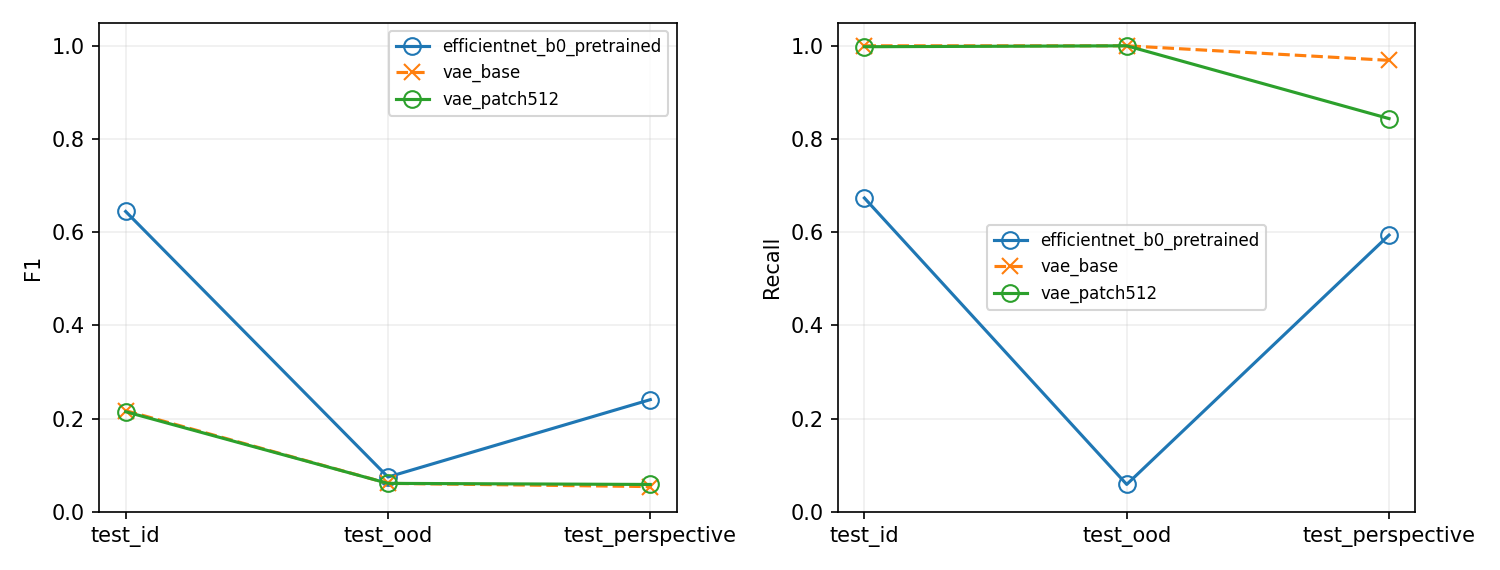

In [2]:
display(metrics[['experiment_id', 'split', 'n', 'prevalence', 'precision', 'recall', 'f1', 'pr_auc', 'fpr', 'flagged_rate']].round(4))
display(pd.read_csv(OUT / 'domain_shift.csv').round(4))
display(Image(filename=str(OUT / 'comparison.png')))


### efficientnet_b0_pretrained

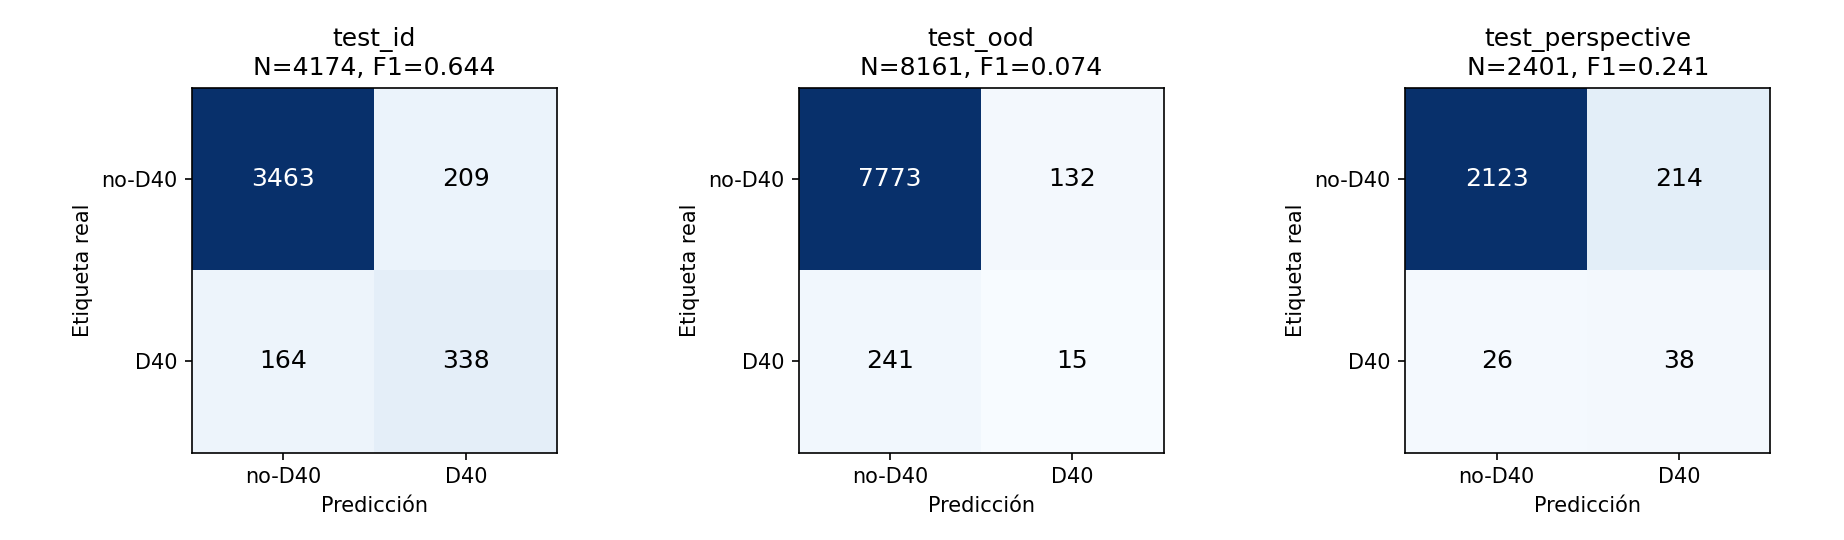

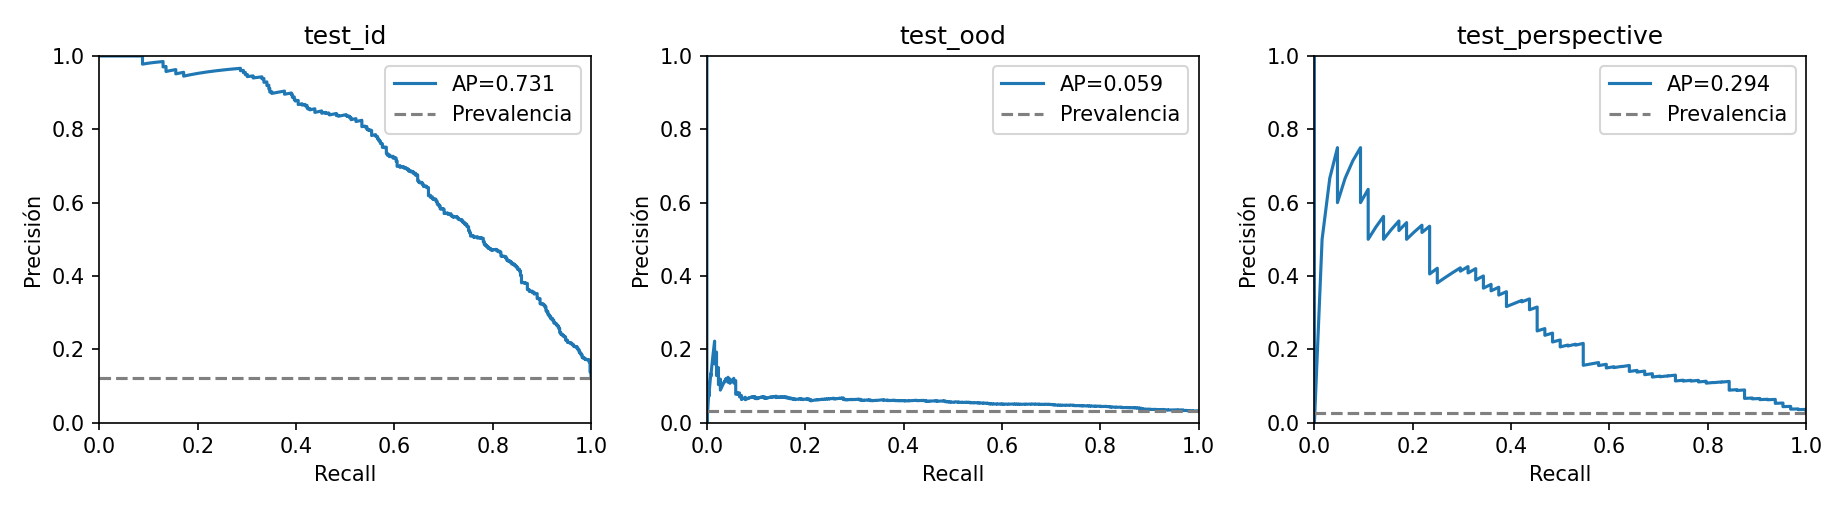

### vae_base

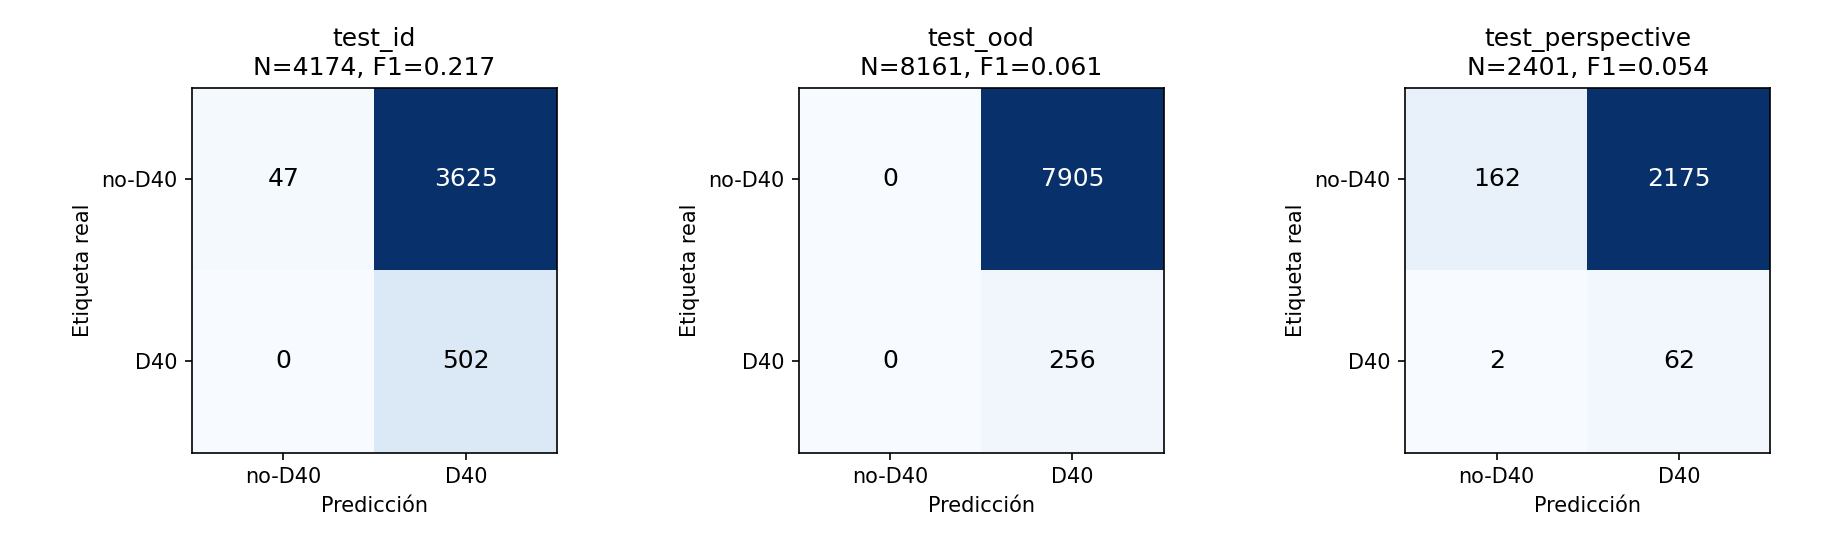

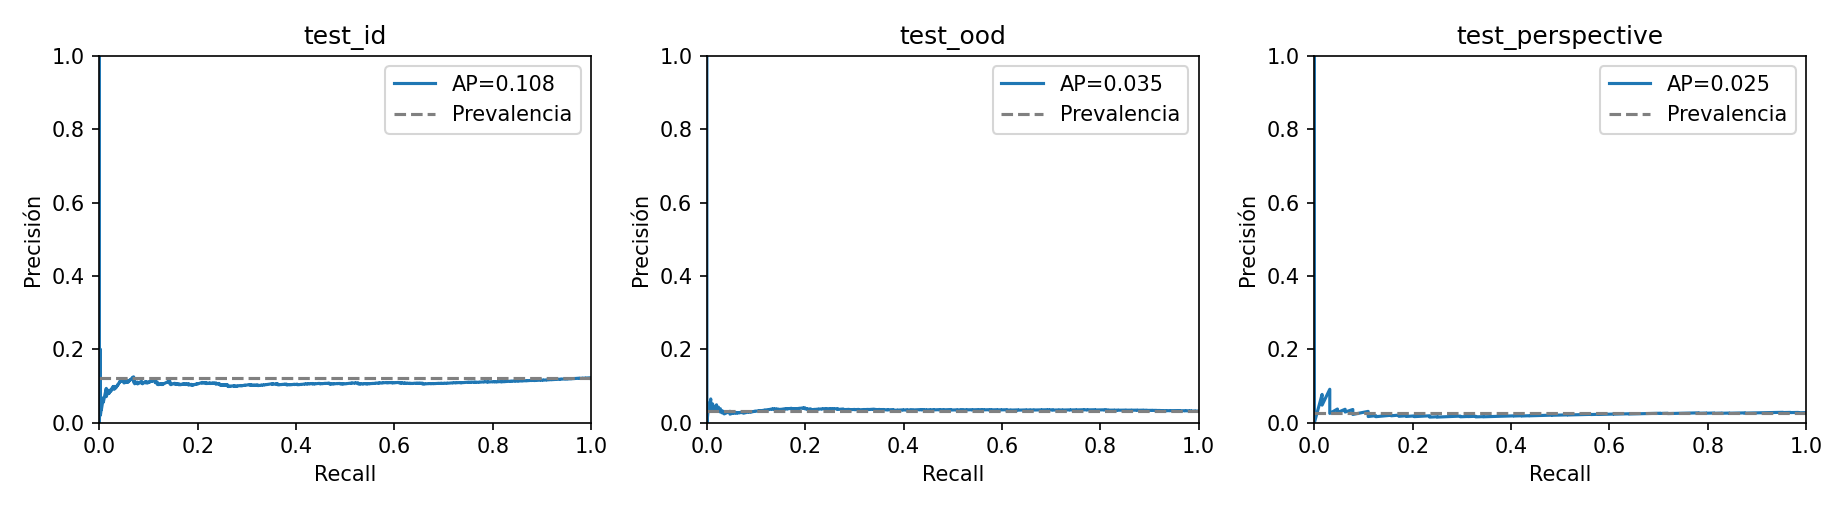

### vae_patch512

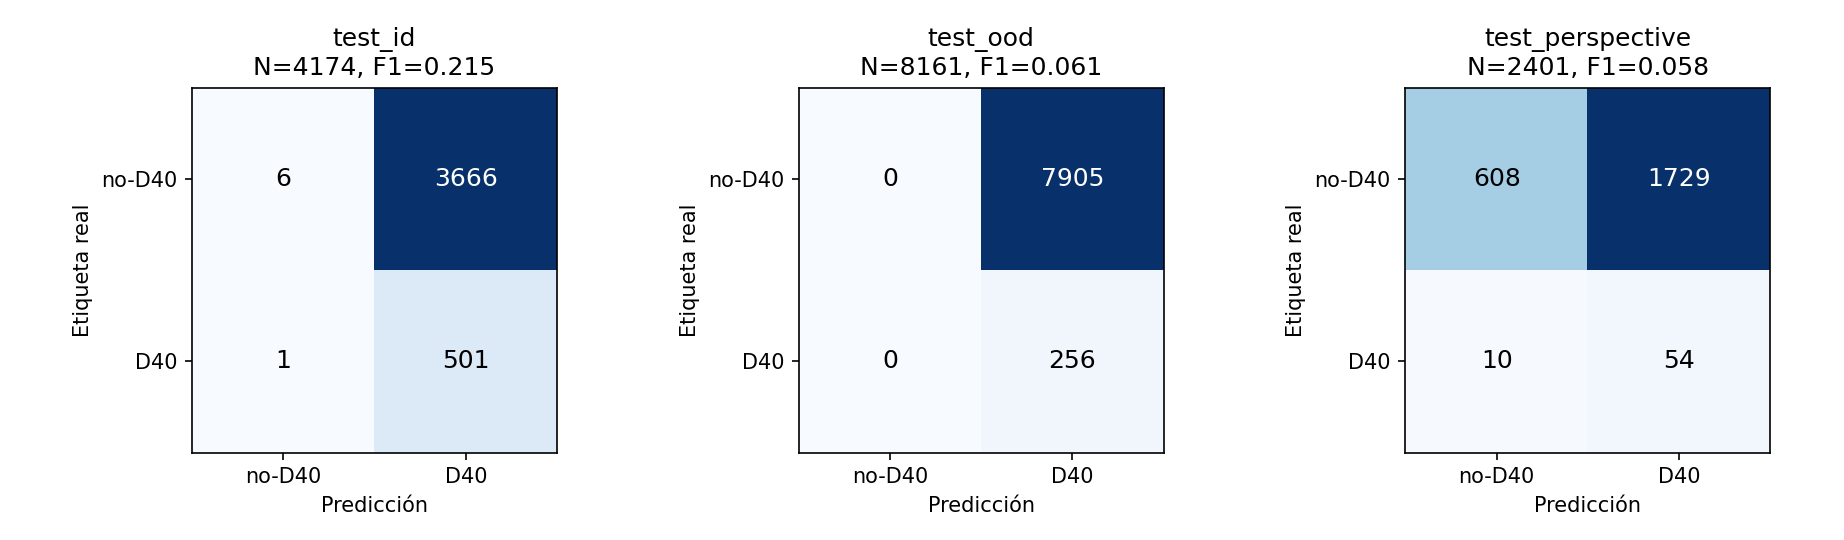

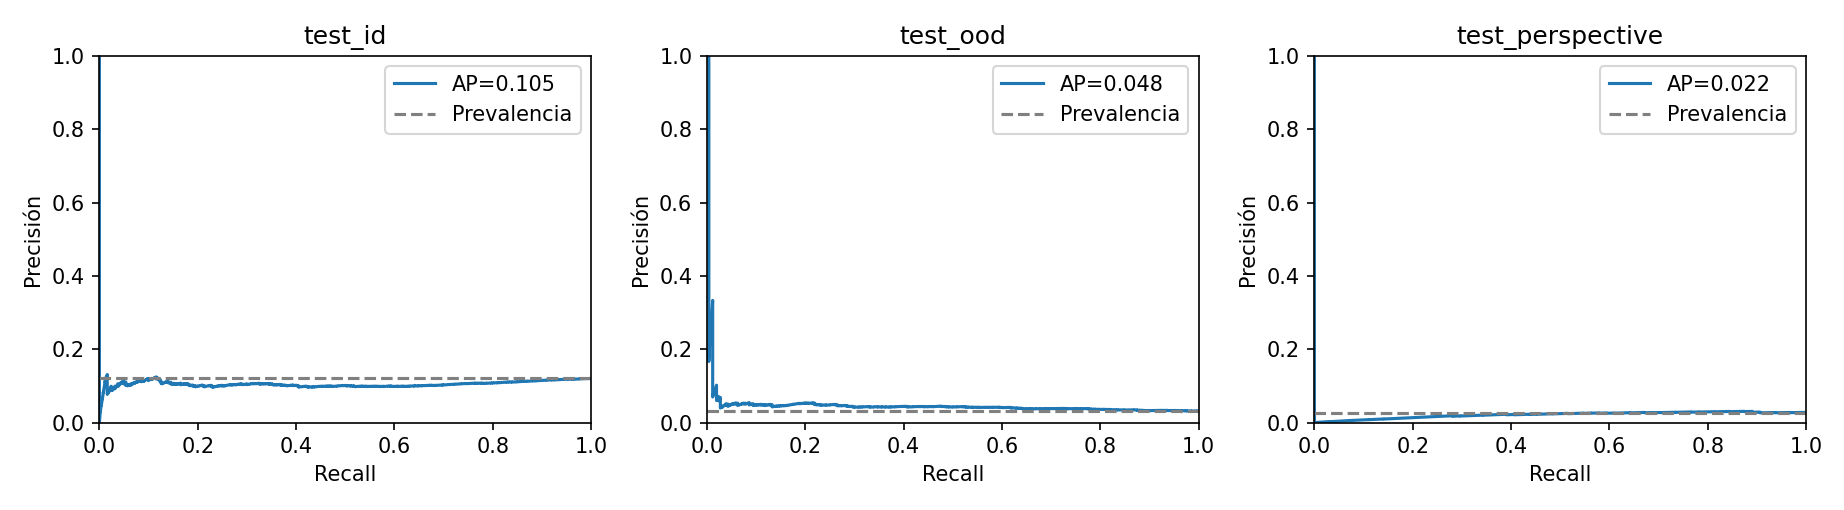

In [3]:
for experiment in metrics.experiment_id.unique():
    display(Markdown(f'### {experiment}'))
    display(Image(filename=str(OUT / experiment / 'confusion.png')))
    display(Image(filename=str(OUT / experiment / 'precision_recall.png')))


## Errores, selección de casos y auditoría
Los ejemplos son una muestra uniforme reproducible (semilla 42) de hasta tres TP/TN/FP/FN por dominio. Si un grupo está vacío se informa: no se cambia el umbral para fabricar ejemplos. `error_groups.json` desglosa otros daños y países; las clases de daño pueden solaparse. La explicación visual de sombras, textura o fondo requiere abrir la foto y el mapa, no inferirla de un CSV.

`archive_discrepancies.csv` conserva diferencias entre los números archivados y los recalculados. En `vae_base/val` hay un caso en el límite numérico del umbral: el CSV leído en float64 da 502 TP/2 FN frente a 503 TP/1 FN archivados. Se preservan scores y umbral, sin corregir a mano. Los tres tests de ambos VAE reproducen las matrices archivadas.

In [4]:
display(pd.read_csv(OUT / 'case_coverage.csv'))
display(pd.read_csv(OUT / 'cases.csv')[['experiment_id', 'sample_id', 'split', 'outcome', 'y_score', 'threshold']])
display(pd.read_csv(OUT / 'archive_discrepancies.csv'))
display(pd.read_csv(OUT / 'latency_reported.csv'))
print(json.dumps(status, indent=2, ensure_ascii=False))


,experiment_id,split,outcome,available
0,efficientnet_b0_pretrained,test_id,TP,338
1,efficientnet_b0_pretrained,test_id,TN,3463
2,efficientnet_b0_pretrained,test_id,FP,209
3,efficientnet_b0_pretrained,test_id,FN,164
4,efficientnet_b0_pretrained,test_ood,TP,15
5,efficientnet_b0_pretrained,test_ood,TN,7773
6,efficientnet_b0_pretrained,test_ood,FP,132
7,efficientnet_b0_pretrained,test_ood,FN,241
8,efficientnet_b0_pretrained,test_perspective,TP,38
9,efficientnet_b0_pretrained,test_perspective,TN,2123


,experiment_id,sample_id,split,outcome,y_score,threshold
0,efficientnet_b0_pretrained,Japan__Japan_010336,test_id,FN,0.142938,0.752365
1,efficientnet_b0_pretrained,Japan__Japan_005587,test_id,FN,0.506489,0.752365
2,efficientnet_b0_pretrained,Japan__Japan_008908,test_id,FN,0.508884,0.752365
3,efficientnet_b0_pretrained,India__India_001449,test_id,FP,0.775572,0.752365
4,efficientnet_b0_pretrained,Japan__Japan_005211,test_id,FP,0.800429,0.752365
...,...,...,...,...,...,...
85,vae_patch512,China_Drone__China_Drone_000042,test_perspective,TN,0.002684,0.003435
86,vae_patch512,China_Drone__China_Drone_000778,test_perspective,TN,0.001539,0.003435
87,vae_patch512,China_Drone__China_Drone_000955,test_perspective,TP,0.003756,0.003435
88,vae_patch512,China_Drone__China_Drone_002145,test_perspective,TP,0.005355,0.003435


,experiment_id,split,metric,archived,recomputed
0,vae_base,val,tp,503.000000,502.000000
1,vae_base,val,fn,1.000000,2.000000
2,vae_base,val,f1,0.217373,0.216987
3,vae_base,val,precision,0.121969,0.121756
4,vae_base,val,recall,0.998016,0.996032


,experiment_id,device,reported_median_ms,image_size,scope,comparability
0,efficientnet_b0_pretrained,cpu,230.339437,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
1,vae_base,cpu,9.320800,128,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
2,vae_base,cuda,2.283550,128,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
3,vae_patch512,cpu,95.570500,512,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
4,vae_patch512,cuda,5.158100,512,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...


{
  "dataset_version": "dataset_v1",
  "splits_sha256": "c7b4690943e597a382ab0f7a8ad1298317f267901476b72111a1b1a8041a8614",
  "sources": [
    {
      "family": "efficientnet",
      "experiment_id": "efficientnet_b0_pretrained",
      "predictions_sha256": "850e3e0c77c072b7d7b1ba52b124d1301aee20d4a23fe0d60ca4e9926228206d",
      "config_sha256": "8eba2b7de7148ded5734da5a29b480e1281586d6e307513fd591cb3446070884",
      "external_predictions_sha256": null
    },
    {
      "family": "vae",
      "experiment_id": "vae_base",
      "predictions_sha256": "6b34e92e6a30ed8958bac348e0617f7b0337397348c8d6d209e778bfbc76c54a",
      "config_sha256": "0c069d1671f5f78118f48dcaba4a869e5fa2938b23ac4d8116231b8454f43b73",
      "external_predictions_sha256": null
    },
    {
      "family": "vae",
      "experiment_id": "vae_patch512",
      "predictions_sha256": "b150e30f2fefe8ea230578cd4773338cd2566db4dfedc3fca62afcaea6d7ebb0",
      "config_sha256": "100a1fe00bda5fac44db1448157f2211e34f58e1b5652f

## Conclusión provisional y pendientes
Ambos VAE activan todas las imágenes de Noruega: 256 TP y 7905 FP; recall 1, precisión 0.0314 y F1 0.0608. No son clasificadores D40 útiles con el umbral fijado. El score de reconstrucción detecta anomalías generales, no necesariamente baches.

EfficientNet-B0 se entrenó sin limitar datos: seis épocas con parada temprana y checkpoint seleccionado en la época 2. Con umbral fijo de validación 0.7523648738861084 obtuvo F1 0.6444 interno, 0.0744 Noruega y 0.2405 China_Drone. En Noruega omitió 241 de 256 baches: no está lista para despliegue. Faltan resultados verificables de ResNet y Guatemala.

Se generaron e inspeccionaron 36 Grad-CAM B0; la revisión está en `reports/xai_evaluation/efficientnet_b0_pretrained/gradcam/visual_review.md`. Las latencias de `latency_reported.csv` siguen siendo forward del entrenador; los benchmarks nuevos separados en `benchmark_cpu` y `benchmark_mps` dan medianas 96.467 y 8.748 ms (Apple M4 Pro, batch 1, cuatro hilos CPU, 200 mediciones y 20 calentamientos). No incluyen I/O ni preprocesamiento. Para completar la comparación, incorporar checkpoints ResNet/VAE y evaluar Guatemala revisada sin retocar umbrales.